# Energy Stock Portfolio Analysis

How have oil majors, utilities and renewables performed on risk and return over 2021–2025, and what would an optimised energy portfolio have looked like?

In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # lets this notebook import from src/

import pandas as pd
from src.config import BENCHMARK, TICKER_SECTOR
from src.data import load_prices
from src import metrics, plots, optimise

pd.options.display.float_format = "{:.3f}".format

# Loading and Cleaning

In [3]:
prices = load_prices()          # downloads on the first run, then reads data/prices.csv
prices = metrics.clean_prices(prices)
prices.tail()

,XOM,CVX,SHEL,BP,TTE,NEE,DUK,SO,NGG,FSLR,ENPH,BEP,SPY
Date,,,,,,,,,,,,,
2025-12-24,116.875,146.412,70.896,33.081,63.121,78.732,114.483,85.078,75.505,272.210,32.850,26.482,685.029
2025-12-26,116.768,145.945,70.867,33.043,63.111,78.693,114.191,85.078,75.651,269.690,33.000,26.415,684.960
2025-12-29,118.160,146.888,71.168,33.216,63.467,78.556,114.522,85.439,75.466,268.250,33.130,26.347,682.519
2025-12-30,118.611,148.172,71.860,33.506,63.487,78.810,114.678,85.468,75.778,264.300,32.190,25.980,681.686
2025-12-31,117.973,148.270,71.519,33.486,63.971,78.566,114.220,85.107,75.368,261.230,32.050,26.038,676.635


# Returns

In [4]:
returns = metrics.daily_returns(prices)
market = returns.pop(BENCHMARK)  # separate SPY from the energy stocks
print(f"{returns.shape[0]} trading days, {returns.shape[1]} stocks")

1254 trading days, 12 stocks


# Metrics Table

In [5]:
summary = metrics.summary_table(returns, market)
benchmark = metrics.summary_table(market.to_frame(), market)
pd.concat([summary, benchmark])

# Sector Advantages #

summary.groupby(TICKER_SECTOR).mean()

,Annual return,Volatility,Sharpe,Max drawdown,Beta
Oil & Gas,0.197,0.265,0.593,-0.255,0.580
Renewables,-0.044,0.506,-0.159,-0.688,1.108
Utilities,0.096,0.212,0.290,-0.329,0.368


# Charts

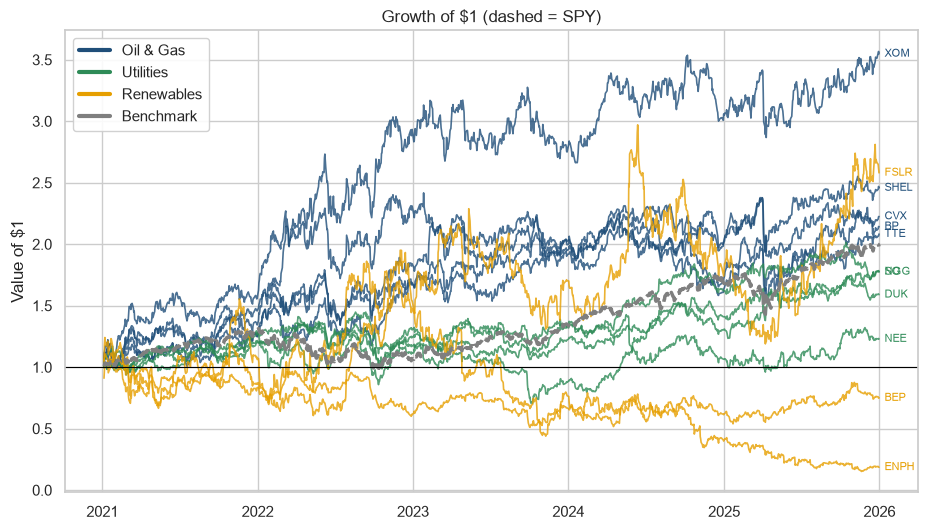

In [6]:
plots.plot_cumulative_returns(returns, market, save_as="cumulative_returns");

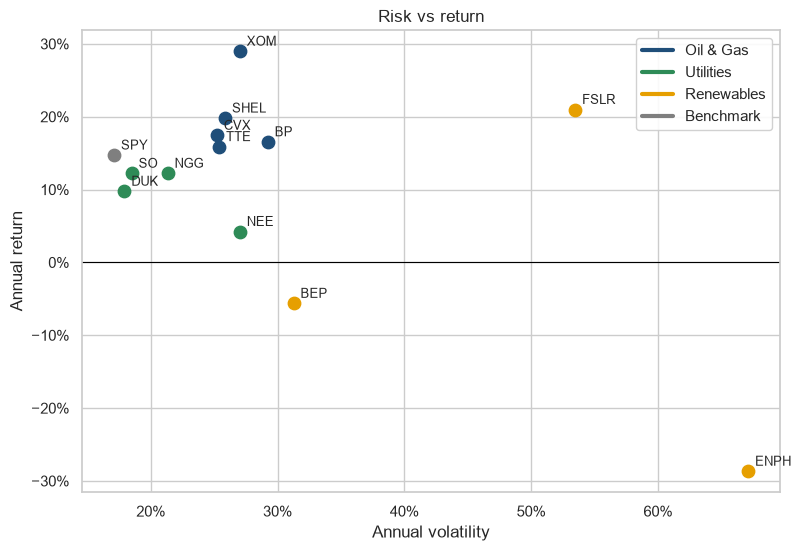

In [7]:
plots.plot_risk_return(pd.concat([summary, benchmark]), save_as="risk_return");

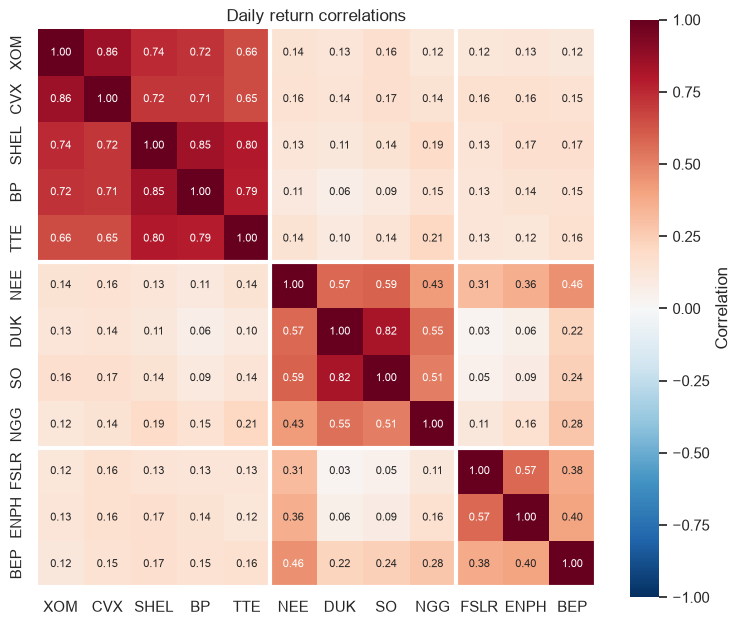

In [8]:
plots.plot_correlation_heatmap(returns, save_as="correlation_heatmap");

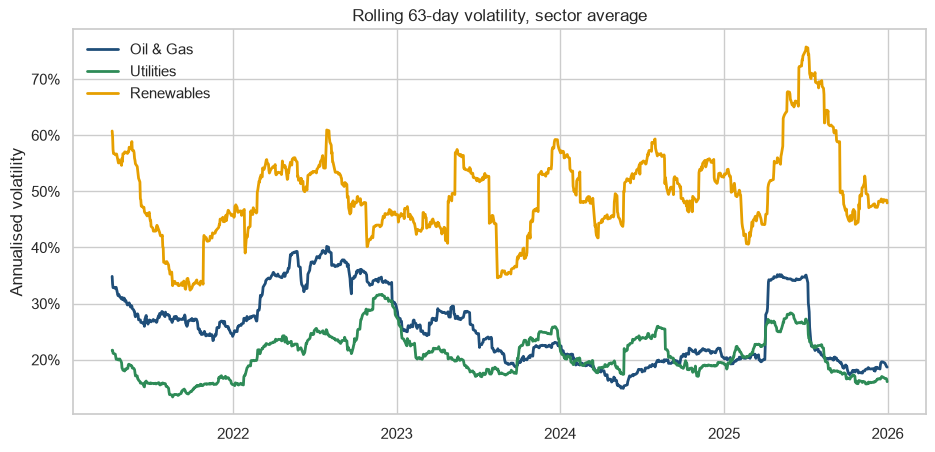

In [9]:
plots.plot_rolling_volatility(returns, save_as="rolling_volatility");

# Comparing 3 Portfolios

In [10]:
mean_returns, cov = optimise.annual_inputs(returns)

portfolios = {
    "Max Sharpe": optimise.max_sharpe_weights(returns),
    "Min variance": optimise.min_variance_weights(returns),
    "Equal weight": pd.Series(1 / returns.shape[1], index=returns.columns),
}

rows = {}
for name, w in portfolios.items():
    ret, vol, sharpe = optimise.portfolio_performance(w.values, mean_returns, cov)
    rows[name] = {"Return": ret, "Volatility": vol, "Sharpe": sharpe}
pd.DataFrame(rows).T

,Return,Volatility,Sharpe
Max Sharpe,0.238,0.182,1.092
Min variance,0.139,0.143,0.694
Equal weight,0.145,0.183,0.575


# What Each Portfolio Holds

In [11]:
# Weights of each portfolio (hide stocks with under 0.5% in all of them)
weights = pd.DataFrame(portfolios)
weights[(weights > 0.005).any(axis=1)].sort_values("Max Sharpe", ascending=False)

,Max Sharpe,Min variance,Equal weight
XOM,0.502,0.017,0.083
SO,0.225,0.161,0.083
NGG,0.145,0.123,0.083
FSLR,0.128,0.026,0.083
SHEL,0.000,0.034,0.083
BEP,0.000,0.066,0.083
DUK,0.000,0.340,0.083
CVX,0.000,0.111,0.083
NEE,0.000,0.000,0.083
BP,0.000,0.000,0.083


# Efficient Frontier

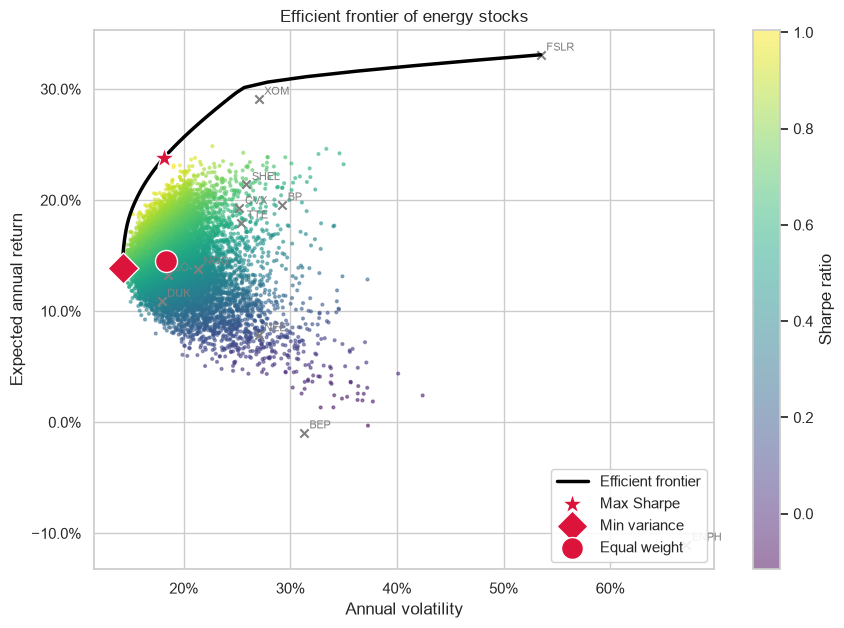

In [12]:
random_ports = optimise.random_portfolios(returns)
frontier = optimise.efficient_frontier(returns)
special = {name: (r["Volatility"], r["Return"]) for name, r in rows.items()}

plots.plot_efficient_frontier(random_ports, frontier, special,
                              optimise.single_stock_points(returns),
                              save_as="efficient_frontier");

## Findings

- **Oil & gas led on risk-adjusted return.** The sector averaged a Sharpe ratio of 0.59, against 0.29 for utilities and −0.16 for renewables. ExxonMobil was the standout: 29.0% a year (Sharpe 0.92), turning $1 into $3.55 against $1.98 for the S&P 500. It was the only stock to beat SPY's Sharpe of 0.63.

- **2022 is where the sectors split.** Oil and gas stocks gained an average of 50% in 2022 while SPY fell 18%, as gas and oil prices spiked after the invasion of Ukraine. Oil volatility peaked at about 40% in July 2022, then settled back below 25%.

- **Renewables were the riskiest sector by far.** Their volatility stayed between 44% and 55% every year. Enphase fell 81% over the period, with a maximum drawdown of 92%. First Solar returned 21% a year, but only with 54% volatility.

- **Diversifying within oil does little.** The five oil majors have an average correlation of 0.75 with each other, but only 0.14 with utilities and renewables. Holding a mix of sectors reduces risk far more than holding several oil companies.

- **NextEra behaves like a utility but carried renewables-style risk.** Its correlation is 0.53 with other utilities, 0.38 with renewables and 0.14 with oil. Yet its maximum drawdown was −45% and its beta 0.59, against 0.24–0.36 for the other utilities, reflecting its exposure to wind and solar development and to interest rates.

- **The optimiser combines sectors.** The max-Sharpe portfolio holds 50% XOM, 23% Southern Company, 15% National Grid and 13% First Solar. That gives an expected 23.8% return at 18.2% volatility, a Sharpe of 1.09 against 0.66 for SPY on the same basis. Capping any one stock at 25% only lowers this to 1.04. The minimum-variance portfolio, led by 34% Duke Energy, reached 14.3% volatility, lower than SPY's 17.1%.

## Limitations

- **Hindsight bias.** The optimal weights were chosen using the same 2021–2025 data they're judged on, so the 50% weighting in XOM partly reflects knowing it was the best performer. A fair test would optimise on 2021–2023 and evaluate on 2024–2025.

- **An unusual window.** The 2022 energy crisis flatters oil and gas. A different five years, such as 2015–2020, would likely tell a very different story.

- **Selection bias.** The stocks were picked in 2026 from companies that still exist and are well known, which leaves out firms that failed along the way.

- **Two return measures.** The metrics table uses compound (geometric) returns, while the optimiser uses average daily returns × 252. High volatility makes these differ a lot: First Solar shows 21% compound but 33% average.

- **Volatility understates tail risk.** Mean-variance optimisation treats risk as standard deviation, which doesn't capture crashes like Enphase's 92% drawdown.

- **Simplified assumptions.** The risk-free rate is fixed at 4%, though actual US rates rose from near 0% in 2021 to about 5% by 2023. There are no trading costs, taxes or rebalancing. All prices are in US dollars, so a UK investor would also face exchange-rate risk.

- **A small sample.** With only three renewables stocks, one extreme name (Enphase) heavily skews the sector averages.
